#### Surrogado lineal de las PCs: ¿basta la estructura lineal para que el XGB vea temporales?
Surrogado multivariante por aleatorización de fases (mismas fases para todas las PCs) + ajuste de amplitudes (AAFT):
- conserva la **marginal** de cada PC (exacta) y sus **autocorrelaciones y correlaciones cruzadas** (aprox.), con la estacionalidad aparte;
- destruye todo lo **no lineal**: qué PCs coinciden en los extremos, formas de tormenta, asimetrías temporales.

Lectura: si la f del surrogado cae como la del PVAR (máx. anual ≈ 1.9) → ningún generador lineal sirve. Si se queda cerca de la histórica (≈ 2.6) → la estructura lineal basta y el problema es el PVAR concreto.

In [1]:
import pandas as pd
import numpy as np
import xarray as xr

import matplotlib.pyplot as plt

from xgboost import XGBRegressor
from scipy.stats import skew

In [2]:
import pickle, json, glob

#### Regresión final de 04B y suavizado de 05C
xgb_final = XGBRegressor()
xgb_final.load_model("outputs/xgb_pit/xgb_final.json")
feat = json.load(open("outputs/xgb_pit/xgb_features.json"))
cols, lags = feat["columns"], feat["lags_h"]
SUAVIZADO_H = pickle.load(open("outputs/xgb_pit/escala.pkl", "rb")).get("suavizado_h", 1)

def f_desde_pcs(pcs):
    """PCs 6-horarias → f horaria (mismos lags y columnas que 04B, interpolada y suavizada como en 05C)."""
    X = pd.concat({f"l{l}": pcs.shift(freq=pd.Timedelta(hours=l)) for l in lags}, axis=1).reindex(pcs.index)
    X.columns = [f"{c_}_l{l[1:]}" for l, c_ in X.columns]
    X = X.dropna()[cols]
    f_6h = pd.Series(xgb_final.predict(X), index=X.index)
    f_h = f_6h.resample("h").interpolate()
    if SUAVIZADO_H > 1:
        f_h = f_h.rolling(SUAVIZADO_H, center=True, min_periods=1).mean()
    return f_h

#### PCs históricas y estandarizador estacional de 03 (el surrogado se hace sin estacionalidad)
pcs_hist = pd.read_csv("outputs/seleccion_6h/pcs_seleccionadas_6h.csv", index_col=0, parse_dates=True).loc["1941":"2025"]
harm_std_pcs = pickle.load(open("outputs/var_6h/harm_std_pcs.pkl", "rb"))
pcs_z = harm_std_pcs.transform(pcs_hist)
print(pcs_z.shape, pcs_z.isna().sum().sum())

(124184, 30) 0


In [3]:
def surrogado(z, rng, amplitud=True):
    """Aleatorización de fases multivariante (mismas fases en todas las columnas) + AAFT opcional."""
    zv = z.values
    n = len(zv)
    Z = np.fft.rfft(zv - zv.mean(axis=0), axis=0)
    fases = np.exp(2j * np.pi * rng.random(Z.shape[0]))
    fases[0] = 1
    if n % 2 == 0:
        fases[-1] = 1                                       # la de Nyquist tiene que ser real
    s = np.fft.irfft(Z * fases[:, None], n=n, axis=0) + zv.mean(axis=0)
    if amplitud:                                            # misma marginal que la histórica, columna a columna
        orden = np.sort(zv, axis=0)
        rangos = s.argsort(axis=0).argsort(axis=0)
        s = np.take_along_axis(orden, rangos, axis=0)
    return pd.DataFrame(s, index=z.index, columns=z.columns)

In [4]:
#### Comprobación del surrogado: autocorrelación, correlación cruzada y asimetría
s0 = surrogado(pcs_z, np.random.default_rng(0))

def acf(x, lags_):
    return [x.autocorr(l) for l in lags_]
lags_6h = [1, 2, 4, 8]                                      # 6, 12, 24, 48 h
for c_ in ["msl_PC1", "grad_PC2", "grad_PC3"]:
    print(f"{c_:9s} ACF hist {np.round(acf(pcs_z[c_], lags_6h), 2)} | surr {np.round(acf(s0[c_], lags_6h), 2)}")

cc_h, cc_s = pcs_z.corr().values, s0.corr().values
print(f"correlación cruzada (lag 0): máx |hist − surr| = {np.abs(cc_h - cc_s).max():.3f}")
print(f"asimetría grad_PC2/3: hist {skew(pcs_z['grad_PC2']):.2f} / {skew(pcs_z['grad_PC3']):.2f} | "
      f"surr {skew(s0['grad_PC2']):.2f} / {skew(s0['grad_PC3']):.2f}  (iguales por construcción)")

msl_PC1   ACF hist [0.96 0.91 0.85 0.61] | surr [0.96 0.91 0.85 0.61]
grad_PC2  ACF hist [0.91 0.77 0.6  0.27] | surr [0.9  0.76 0.59 0.27]
grad_PC3  ACF hist [0.89 0.74 0.59 0.29] | surr [0.89 0.73 0.58 0.28]
correlación cruzada (lag 0): máx |hist − surr| = 0.008
asimetría grad_PC2/3: hist -0.01 / 0.57 | surr -0.01 / 0.57  (iguales por construcción)


In [5]:
#### f con PCs históricas, surrogados (con y sin ajuste de amplitudes) y PVAR
q = [0.5, 0.9, 0.99, 0.999]

def resumen_f(f_h):
    am = f_h.groupby(f_h.index.year).max()
    return pd.Series({**{f"q{int(p*1000)/10:g}": f_h.quantile(p) for p in q}, "máx anual medio": am.mean()})

f_hist = f_desde_pcs(pcs_hist).loc["1942":]
filas = {"histórica": resumen_f(f_hist)}

for nombre, amp in [("surrogado AAFT (marginal real)", True), ("surrogado gaussiano", False)]:
    res = []
    for i in range(5):
        s = surrogado(pcs_z, np.random.default_rng(i), amplitud=amp)
        res.append(resumen_f(f_desde_pcs(harm_std_pcs.inverse_transform(s)).loc["1942":]))
    filas[nombre] = pd.concat(res, axis=1).median(axis=1)
    print(nombre, "ok")

ficheros = sorted(glob.glob("outputs/var_6h/simulaciones/sim_*.parquet"))
res = [resumen_f(f_desde_pcs(pd.read_parquet(fic).astype("float64")).loc["1941":]) for fic in ficheros[:5]]
filas["PVAR"] = pd.concat(res, axis=1).median(axis=1)

tabla = pd.DataFrame(filas).T
print(tabla.round(3).to_string())

surrogado AAFT (marginal real) ok
surrogado gaussiano ok
                                  q50    q90    q99  q99.9  máx anual medio
histórica                      -0.059  0.972  1.951  2.644            2.619
surrogado AAFT (marginal real)  0.025  0.814  1.432  1.865            1.857
surrogado gaussiano             0.065  0.858  1.484  1.912            1.909
PVAR                            0.061  0.869  1.507  1.925            1.916


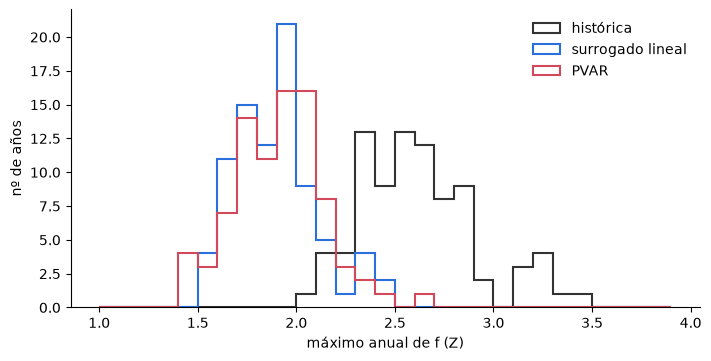

In [6]:
#### Distribución de los máximos anuales de f
fig, ax = plt.subplots(figsize=(7, 3.5), constrained_layout=True)
am_h = f_hist.groupby(f_hist.index.year).max()
s = surrogado(pcs_z, np.random.default_rng(0))
f_s = f_desde_pcs(harm_std_pcs.inverse_transform(s)).loc["1942":]
f_p = f_desde_pcs(pd.read_parquet(ficheros[0]).astype("float64")).loc["1941":]
for serie, color, nombre in [(am_h, "0.2", "histórica"),
                             (f_s.groupby(f_s.index.year).max(), "#2a6fdb", "surrogado lineal"),
                             (f_p.groupby(f_p.index.year).max(), "#d1495b", "PVAR")]:
    ax.hist(serie, bins=np.arange(1, 4, 0.1), histtype="step", lw=1.5, color=color, label=nombre)
ax.set(xlabel="máximo anual de f (Z)", ylabel="nº de años")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()